In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

neighbourhoods = pd.read_csv('../02_Data/processed/neighbourhoods_clean.csv', low_memory=False)

In [27]:
# compare neighbourhood
nb_stats = listings.groupby('neighbourhood').agg(
    listings = ('id', 'count'),
    median_price = ('price', 'median'),
    mean_price = ('price', 'mean'),
    pct_entire_home = ('room_type', lambda s: round((s == 'Entire home/apt').mean()*100,1)),
    median_reviews = ('number_of_reviews', 'median'),
    missing_price_pct = ('price', lambda s: round(s.isna().mean()*100,2))
).reset_index()

nb_stats['share_of_city_%'] = (nb_stats['listings']/ nb_stats['listings'].sum()*100).round(1)
nb_stats = nb_stats.sort_values('median_price', ascending=False).reset_index(drop=True)
display(nb_stats)



,neighbourhood,listings,median_price,mean_price,pct_entire_home,median_reviews,missing_price_pct,share_of_city_%
0,la Marina del Prat Vermell,3,335.860,306.776667,66.7,3.0,0.00,0.0
1,Diagonal Mar i el Front Marítim del Poblenou,119,325.000,386.666923,87.4,28.0,12.61,0.8
2,la Vila Olímpica del Poblenou,135,272.460,285.234959,88.1,21.0,8.89,0.9
3,la Sagrada Família,910,248.500,267.083615,77.4,26.5,11.54,6.0
4,el Fort Pienc,424,247.500,250.569437,74.1,29.5,12.03,2.8
...,...,...,...,...,...,...,...,...
64,Torre Baró,1,57.300,57.300000,100.0,0.0,0.00,0.0
65,la Font d'en Fargues,22,47.860,202.964211,22.7,0.5,13.64,0.1
66,la Prosperitat,16,47.850,96.017500,31.2,0.0,25.00,0.1
67,la Trinitat Vella,3,44.055,44.055000,0.0,21.0,33.33,0.0


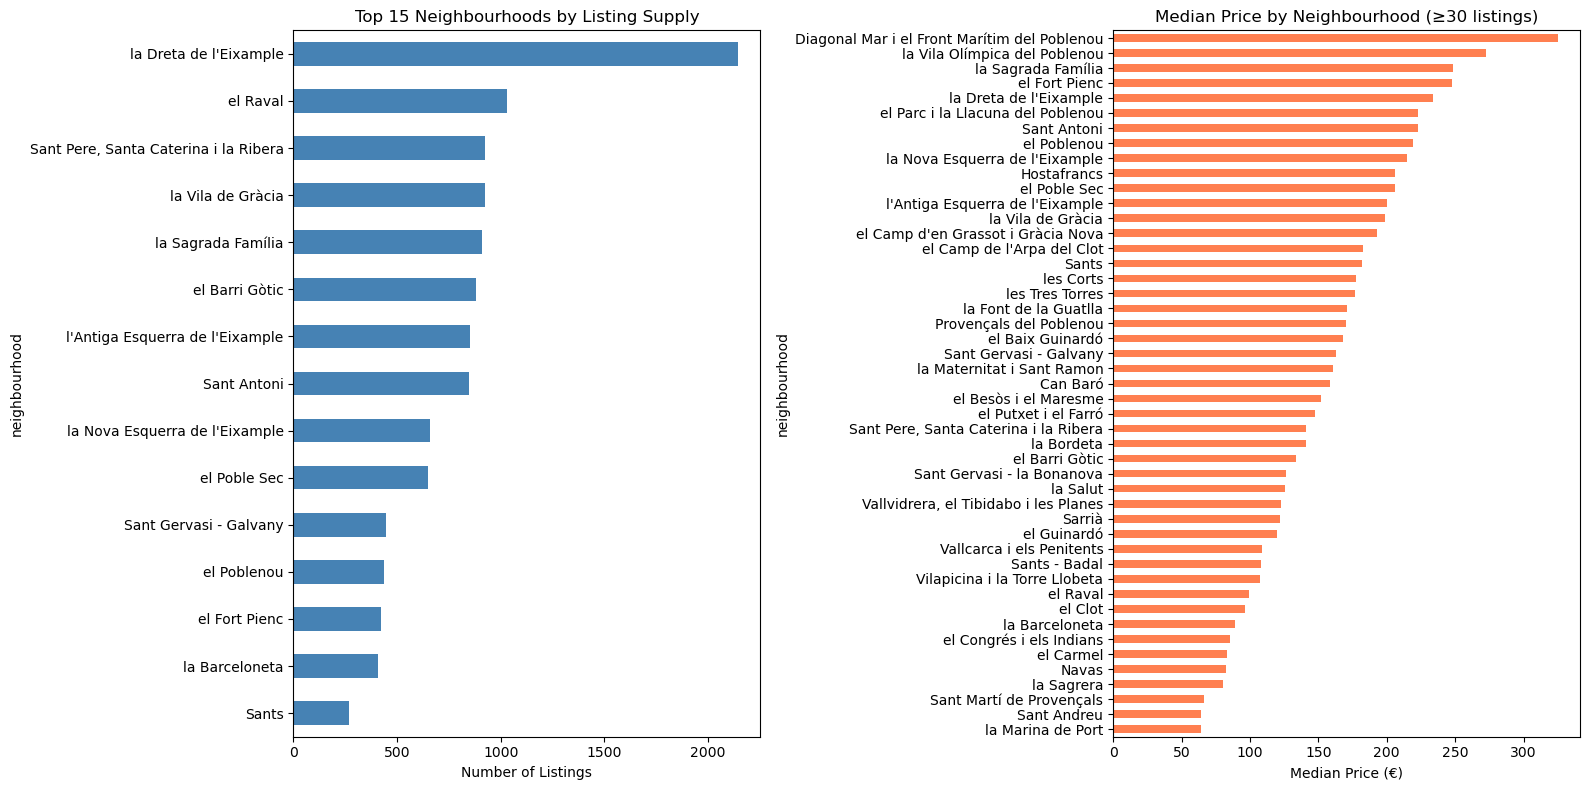

In [28]:
# For charting, only reliable samples (>= 30 listings)
reliable = nb_stats[nb_stats['listings']>= 30].sort_values('median_price', ascending = True)

fig, ax = plt.subplots(1, 2, figsize=(16, 8))

# 1 Supply
nb_stats.sort_values('listings' ,ascending = True).tail(15).plot.barh(x='neighbourhood' , y='listings' , ax=ax[0], color='steelblue', legend=False)
ax[0].set_title('Top 15 Neighbourhoods by Listing Supply')
ax[0].set_xlabel('Number of Listings')

# 2 price
reliable.plot.barh(x ='neighbourhood', y='median_price', ax=ax[1], color='coral', legend=False)
ax[1].set_title('Median Price by Neighbourhood (≥30 listings)')
ax[1].set_xlabel('Median Price (€)')

plt.tight_layout()
plt.show()


In [31]:
gap_analysis = listings.groupby(['neighbourhood','room_type']).agg(
    listings=('id','count'),
    median_price=('price', 'median'),
    median_reviews=('number_of_reviews', 'median')
).reset_index()

# Candidates: >=10 listings (some signal), high median price, low supply
candidates = gap_analysis[
    (gap_analysis['listings'] >= 10) &
    (gap_analysis['listings'] <= 50) &
    (gap_analysis['median_price'] >= 150)
].sort_values('median_price', ascending = False)

display(candidates)

,neighbourhood,room_type,listings,median_price,median_reviews
35,"Sant Pere, Santa Caterina i la Ribera",Hotel room,16,368.000,0.0
32,Sant Martí de Provençals,Entire home/apt,15,250.000,67.0
116,la Font de la Guatlla,Entire home/apt,42,224.730,60.0
125,la Maternitat i Sant Ramon,Entire home/apt,45,224.120,38.0
161,les Tres Torres,Entire home/apt,34,213.230,14.5
107,la Bordeta,Entire home/apt,40,211.120,9.5
74,el Coll,Entire home/apt,16,196.400,12.0
0,Can Baró,Entire home/apt,25,179.875,14.0
76,el Congrés i els Indians,Entire home/apt,16,178.400,32.0
111,la Dreta de l'Eixample,Hotel room,15,176.000,190.0


In [32]:
# Build consolidated neighbourhood table
nb_table = listings.groupby('neighbourhood').agg(
    listings=('id', 'count'),
    share_of_city_pct=('id', lambda s: round(len(s)/len(listings)*100, 1)),
    median_price=('price', 'median'),
    p25_price=('price', lambda s: s.quantile(0.25)),
    p75_price=('price', lambda s: s.quantile(0.75)),
    pct_entire_home=('room_type', lambda s: round((s=='Entire home/apt').mean()*100, 1)),
    pct_private_room=('room_type', lambda s: round((s=='Private room').mean()*100, 1)),
    median_reviews=('number_of_reviews', 'median'),
    median_accommodates=('accommodates', 'median'),
    missing_price_pct=('price', lambda s: round(s.isna().mean()*100, 2))
).reset_index()

nb_table['price_spread'] = (nb_table['p75_price'] - nb_table['p25_price']).round(0)
nb_table = nb_table.sort_values('median_price', ascending=False)

# Save for Tableau
nb_table.to_csv('../02_Data/processed/neighbourhood_summary.csv', index=False)
print(f" Saved neighbourhood_summary.csv ({len(nb_table)} neighbourhoods)")
display(nb_table.head(15))

 Saved neighbourhood_summary.csv (69 neighbourhoods)


,neighbourhood,listings,share_of_city_pct,median_price,p25_price,p75_price,pct_entire_home,pct_private_room,median_reviews,median_accommodates,missing_price_pct,price_spread
52,la Marina del Prat Vermell,3,0.0,335.860,180.6650,447.4300,66.7,33.3,3.0,3.0,0.00,267.0
2,Diagonal Mar i el Front Marítim del Poblenou,119,0.8,325.000,190.4525,433.2500,87.4,12.6,28.0,4.0,12.61,243.0
64,la Vila Olímpica del Poblenou,135,0.9,272.460,115.6150,384.6250,88.1,7.4,21.0,4.0,8.89,269.0
56,la Sagrada Família,910,6.0,248.500,135.6600,333.0000,77.4,21.8,26.5,4.0,11.54,197.0
35,el Fort Pienc,424,2.8,247.500,107.6700,346.0000,74.1,25.0,29.5,4.0,12.03,238.0
47,la Dreta de l'Eixample,2145,14.0,234.000,141.9350,379.0000,71.1,26.6,19.0,4.0,9.42,237.0
37,el Parc i la Llacuna del Poblenou,161,1.1,223.000,146.6000,298.6100,76.4,18.0,26.0,4.0,14.91,152.0
11,Sant Antoni,846,5.5,222.625,125.7625,324.7475,76.6,23.3,21.0,4.0,11.58,199.0
39,el Poblenou,437,2.9,219.000,118.6850,265.0000,85.4,14.6,11.0,4.0,13.27,146.0
54,la Nova Esquerra de l'Eixample,660,4.3,214.915,104.5175,320.2500,73.0,25.8,7.0,4.0,12.12,216.0
